# Python / Data Science Assignment

**Prepared for:** Tusher Nikam  
**Focus:** Python, Statistics, Machine Learning and Deep Learning


# Project 1 — RNN, LSTM, GRU
## Simple Text Classification: Step-by-Step Comparison

**Goal:** Train three simple models on the same dataset and compare them fairly:

1. Simple RNN
2. LSTM
3. GRU

**Dataset:** IMDb Movie Reviews — binary sentiment classification.

- `0` = Negative
- `1` = Positive
- Input = movie review text
- Output = sentiment

Official dataset:
https://www.tensorflow.org/datasets/catalog/imdb_reviews

### Project flow

```text
Reviews
   ↓
EDA
   ↓
Train / Validation / Test
   ↓
TextVectorization
   ↓
Embedding
   ↓
 ┌──────────┬──────────┬──────────┐
 ↓          ↓          ↓
RNN        LSTM       GRU
 ↓          ↓          ↓
Sentiment prediction
   ↓
Evaluation + comparison
```

# 1. Basic terms

### Text Classification
Predict a category from text.

Example:

```text
"I loved this movie"
        ↓
     Positive
```

### Token
A word or text unit.

### Vocabulary
The collection of words known by the model.

### Sequence
An ordered list of token IDs.

### Embedding
Converts token IDs into numerical vectors.

### RNN
Processes a sequence step by step and keeps hidden information.

### LSTM
A gated RNN designed to keep useful information for longer sequences.

### GRU
A simpler gated RNN using update and reset mechanisms.

### Epoch
One complete pass through training data.

### Batch
A small group of examples processed together.

### Loss
A number that tells us how wrong the predictions are.

### Accuracy
Percentage of correct predictions.

### Precision
Of the predicted positive examples, how many were actually positive?

### Recall
Of the actual positive examples, how many were found?

### F1-score
A combined measure of precision and recall.

# 2. Algorithm

The same pipeline is used for all three models.

```text
1. Load reviews
2. Inspect the dataset
3. Split training data into train + validation
4. Keep the test set untouched
5. Convert text to integer sequences
6. Convert integers to embeddings
7. Train RNN
8. Train LSTM
9. Train GRU
10. Evaluate all three on the same test set
11. Compare accuracy, precision, recall, F1 and parameters
12. Inspect errors
```

Model architectures:

```text
Embedding → SimpleRNN → Dense(1, sigmoid)

Embedding → LSTM      → Dense(1, sigmoid)

Embedding → GRU       → Dense(1, sigmoid)
```

In [1]:
# Install only if needed.
# !pip install tensorflow tensorflow-datasets pandas matplotlib scikit-learn
%pip install tensorflow-datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow.keras import Sequential
from tensorflow.keras.layers import TextVectorization, Embedding
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


# 3. Load the IMDb dataset

TensorFlow Datasets provides the IMDb reviews directly.

The original training split is used to create:

- 80% training
- 20% validation

The original test split stays as the final test set.

In [3]:
import tensorflow as tf
import tensorflow_datasets as tfds
import pandas as pd

# 1. Load IMDB train and test datasets

train_ds = tfds.load(
    "imdb_reviews",
    split="train",
    as_supervised=True
)

test_ds = tfds.load(
    "imdb_reviews",
    split="test",
    as_supervised=True
)

# 2. Convert TensorFlow datasets to Python lists

train_reviews = []
train_labels = []

for review, label in tfds.as_numpy(train_ds):
    train_reviews.append(review.decode("utf-8"))
    train_labels.append(int(label))

test_reviews = []
test_labels = []

for review, label in tfds.as_numpy(test_ds):
    test_reviews.append(review.decode("utf-8"))
    test_labels.append(int(label))

# 3. Create pandas DataFrames

train_raw = pd.DataFrame({
    "review": train_reviews,
    "label": train_labels
})

test_raw = pd.DataFrame({
    "review": test_reviews,
    "label": test_labels
})

# 4. Check dataset

print("Train shape:", train_raw.shape)
print("Test shape:", test_raw.shape)

display(train_raw.head())

Train shape: (25000, 2)
Test shape: (25000, 2)


,review,label
0,This was an absolutely terrible movie. Don't b...,0
1,"I have been known to fall asleep during films,...",0
2,Mann photographs the Alberta Rocky Mountains i...,0
3,This is the kind of film for a snowy Sunday af...,1
4,"As others have mentioned, all the women that g...",1


In [4]:
# Prepare train and test DataFrames

train_df = train_raw.copy()
test_df = test_raw.copy()

# Rename review -> text
train_df = train_df.rename(columns={"review": "text"})
test_df = test_df.rename(columns={"review": "text"})

# Make sure text is string
train_df["text"] = train_df["text"].apply(
    lambda x: x.decode("utf-8") if isinstance(x, bytes) else str(x)
)

test_df["text"] = test_df["text"].apply(
    lambda x: x.decode("utf-8") if isinstance(x, bytes) else str(x)
)

# Make sure labels are integers
train_df["label"] = train_df["label"].astype(int)
test_df["label"] = test_df["label"].astype(int)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())

Train shape: (25000, 2)
Test shape: (25000, 2)


,text,label
0,This was an absolutely terrible movie. Don't b...,0
1,"I have been known to fall asleep during films,...",0
2,Mann photographs the Alberta Rocky Mountains i...,0
3,This is the kind of film for a snowy Sunday af...,1
4,"As others have mentioned, all the women that g...",1


# 4. Understand the dataset

The two classes are:

```text
0 → Negative
1 → Positive
```

Look at real examples before building the model.

In [5]:
# Print a few examples.

for i in range(3):
    label_name = "Positive" if train_df.loc[i, "label"] == 1 else "Negative"

    print("LABEL:", label_name)
    print(train_df.loc[i, "text"][:500])
    print("-" * 80)

LABEL: Negative
This was an absolutely terrible movie. Don't be lured in by Christopher Walken or Michael Ironside. Both are great actors, but this must simply be their worst role in history. Even their great acting could not redeem this movie's ridiculous storyline. This movie is an early nineties US propaganda piece. The most pathetic scenes were those when the Columbian rebels were making their cases for revolutions. Maria Conchita Alonso appeared phony, and her pseudo-love affair with Walken was nothing but
--------------------------------------------------------------------------------
LABEL: Negative
I have been known to fall asleep during films, but this is usually due to a combination of things including, really tired, being warm and comfortable on the sette and having just eaten a lot. However on this occasion I fell asleep because the film was rubbish. The plot development was constant. Constantly slow and boring. Things seemed to happen, but with no explanation of what was c

label
0    12500
1    12500
Name: count, dtype: int64


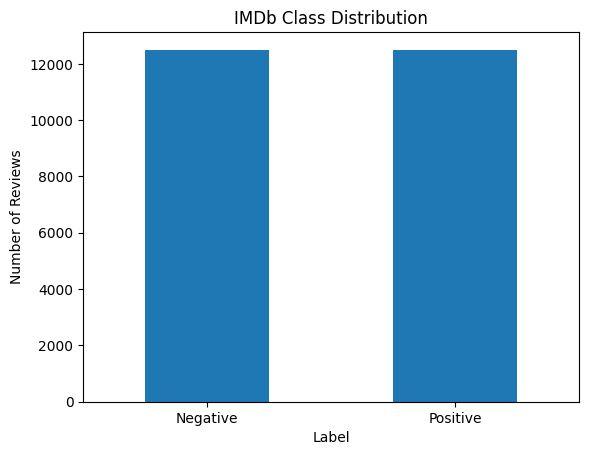

In [6]:
# Class distribution.

print(train_df["label"].value_counts().sort_index())

train_df["label"].value_counts().sort_index().plot(kind="bar")
plt.title("IMDb Class Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Reviews")
plt.xticks([0, 1], ["Negative", "Positive"], rotation=0)
plt.show()

count    25000.000000
mean       233.787200
std        173.733032
min         10.000000
25%        127.000000
50%        174.000000
75%        284.000000
max       2470.000000
Name: word_count, dtype: float64


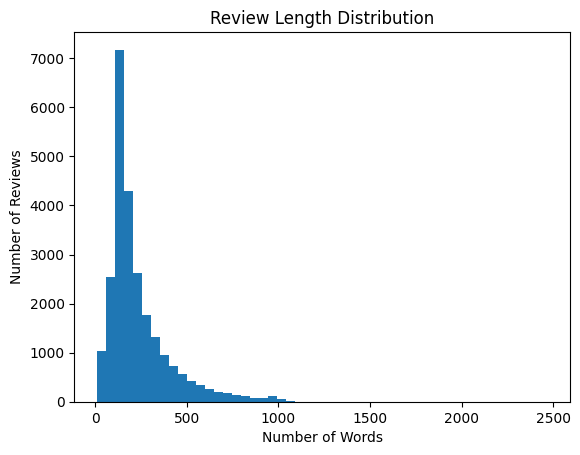

In [7]:
# Simple review-length analysis.

train_df["word_count"] = train_df["text"].str.split().str.len()

print(train_df["word_count"].describe())

plt.hist(train_df["word_count"], bins=50)
plt.title("Review Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.show()

# 5. Train / Validation / Test Split

We do not use the test set during training.

```text
Original training data
        ↓
   ┌────┴────┐
   ↓         ↓
Train      Validation

Original test data
        ↓
Final Test
```

In [8]:
# Shuffle the original training data.

train_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)

split_index = int(len(train_df) * 0.80)

train_part = train_df.iloc[:split_index].copy()
val_part = train_df.iloc[split_index:].copy()

print("Train:", len(train_part))
print("Validation:", len(val_part))
print("Test:", len(test_df))

Train: 20000
Validation: 5000
Test: 25000


# 6. TextVectorization

A neural network cannot directly use:

```text
"This movie was great"
```

So we convert text into integer IDs:

```text
"This movie was great"
        ↓
[12, 45, 8, 231]
```

Then the Embedding layer converts those IDs into vectors.

For a beginner project we use:

- Vocabulary = 10,000 words
- Sequence length = 200
- Embedding size = 64

In [9]:
VOCAB_SIZE = 10000
MAX_LENGTH = 200
EMBEDDING_DIM = 64
RNN_UNITS = 32

vectorizer = TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=MAX_LENGTH
)

# Learn vocabulary from training text only.
vectorizer.adapt(train_part["text"].values)

print("Vocabulary:", len(vectorizer.get_vocabulary()))

Vocabulary: 10000


In [10]:
# See the conversion from text to numbers.

sample = train_part["text"].iloc[0]

print("Original:")
print(sample[:300])

print("\nInteger sequence:")
print(vectorizer([sample]).numpy()[0][:30])

Original:
I watched "Elephant Walk" for the first time in about 30 years and was struck by how similar the story line is to the greatly superior "Rebecca." As others have said, you have the sweet young thing swept off her feet by the alternately charming and brooding lord of the manor, only to find her marria

Integer sequence:
[  10  276 4416 1127   17    2   87   60    8   43 1189  148    3   14
 3492   33   85  718    2   67  363    7    6    2 3073 1636 8928   15
  372   26]


In [11]:
# Convert all text into integer sequences.

X_train = vectorizer(train_part["text"].values).numpy()
y_train = train_part["label"].values

X_val = vectorizer(val_part["text"].values).numpy()
y_val = val_part["label"].values

X_test = vectorizer(test_df["text"].values).numpy()
y_test = test_df["label"].values

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (20000, 200)
X_val: (5000, 200)
X_test: (25000, 200)


# 7. Model 1 — Simple RNN

### Architecture

```text
Integer sequence
      ↓
Embedding
      ↓
SimpleRNN
      ↓
Dense + Sigmoid
      ↓
Negative / Positive
```

Simple RNN carries information using a hidden state.

This is the easiest sequence model in this project.

In [12]:
import tensorflow as tf

print(tf.config.list_physical_devices("GPU"))

[]


In [13]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("CPU devices:", tf.config.list_physical_devices("CPU"))

TensorFlow version: 2.21.0
GPU devices: []
CPU devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [14]:
from sklearn.model_selection import train_test_split

# Features and labels
X = train_df["text"].astype(str)
y = train_df["label"].astype(int)

# Train / Validation split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Test set
X_test = test_df["text"].astype(str)
y_test = test_df["label"].astype(int)

print("Training samples  :", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples      :", len(X_test))

Training samples  : 20000
Validation samples: 5000
Test samples      : 25000


In [15]:
print("Train:")
print(y_train.value_counts())

print("\nValidation:")
print(y_val.value_counts())

print("\nTest:")
print(y_test.value_counts())

Train:
label
1    10000
0    10000
Name: count, dtype: int64

Validation:
label
1    2500
0    2500
Name: count, dtype: int64

Test:
label
1    12500
0    12500
Name: count, dtype: int64


In [16]:
from tensorflow.keras.layers import TextVectorization

MAX_VOCAB_SIZE = 20000
SEQUENCE_LENGTH = 250

vectorizer = TextVectorization(
    max_tokens=MAX_VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH
)

# Learn vocabulary ONLY from training text
vectorizer.adapt(X_train.values)

print("Vocabulary size:", len(vectorizer.get_vocabulary()))

Vocabulary size: 20000


In [17]:
sample_text = X_train.iloc[0]

print("Original:")
print(sample_text)

print("\nTokenized:")
print(vectorizer(sample_text).numpy()[:30])

Original:
Years ago, I found a "bargain bin" copy of this film for a buck or two. In so many ways, this is quite fitting, as when it was made back in 1933, it was truly a cheaply made film by the "poverty row" studio, Majestic. However, while the film is rather derivative, it is STILL well worth watching and provides a few surprises.<br /><br />The story is very, very familiar, as in some Germanic town, the people are upset because of some recent deaths that appear to be the work of vampires! Adding to this familiarity is Dwight Frye. He played Renfield in Dracula, and here he is very, very similar--though he plays a much more harmless weirdo. In this case, he's obsessed with his pet bats and people begin to blame him for the deaths. The film does a good job of providing some "red herrings" (i.e., false leads) and while it doesn't take a genius to figure out Frye may not be responsible, the WHO and WHY are intriguing and make it VERY different from the average horror film. In addition,

In [18]:
# Simple RNN

rnn_model = Sequential([
    Embedding(VOCAB_SIZE, EMBEDDING_DIM),
    SimpleRNN(RNN_UNITS),
    Dense(1, activation="sigmoid")
])

rnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [19]:
print("X_train dtype:", X_train.dtype)
print("X_val dtype:", X_val.dtype)
print("y_train dtype:", y_train.dtype)
print("y_val dtype:", y_val.dtype)

print(type(X_train))
print(type(y_train))

X_train dtype: object
X_val dtype: object
y_train dtype: int64
y_val dtype: int64
<class 'pandas.core.series.Series'>
<class 'pandas.core.series.Series'>


In [21]:
import tensorflow as tf

BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

# Convert pandas Series → NumPy
X_train_np = X_train.astype(str).to_numpy()
X_val_np   = X_val.astype(str).to_numpy()
X_test_np  = X_test.astype(str).to_numpy()

y_train_np = y_train.astype("int32").to_numpy()
y_val_np   = y_val.astype("int32").to_numpy()
y_test_np  = y_test.astype("int32").to_numpy()

# Create TensorFlow datasets
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_np, y_train_np)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val_np, y_val_np)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test_np, y_test_np)
)

# Training pipeline
train_dataset = (
    train_dataset
    .shuffle(10000)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Validation pipeline
val_dataset = (
    val_dataset
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Test pipeline
test_dataset = (
    test_dataset
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Pipeline ready!")

Pipeline ready!


In [22]:
for text_batch, label_batch in train_dataset.take(1):
    print("Text dtype :", text_batch.dtype)
    print("Label dtype:", label_batch.dtype)
    print("Text shape :", text_batch.shape)
    print("Label shape:", label_batch.shape)

Text dtype : <dtype: 'string'>
Label dtype: <dtype: 'int32'>
Text shape : (64,)
Label shape: (64,)


In [24]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SimpleRNN,
    Dense
)

rnn_model = Sequential([
    Input(shape=(1,), dtype=tf.string),

    vectorizer,

    Embedding(
        input_dim=MAX_VOCAB_SIZE,
        output_dim=128,
        mask_zero=True
    ),

    SimpleRNN(64),

    Dense(1, activation="sigmoid")
])

rnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

rnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_1            │ (None, 250)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_2 (Embedding)         │ (None, 250, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,572,417 (9.81 MB)

 Trainable params: 2,572,417 (9.81 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
rnn_history = rnn_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=5
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 35s 94ms/step - accuracy: 0.5586 - loss: 0.6749 - val_accuracy: 0.6034 - val_loss: 0.6404
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 91ms/step - accuracy: 0.8087 - loss: 0.4292 - val_accuracy: 0.7490 - val_loss: 0.5374
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 28s 89ms/step - accuracy: 0.9517 - loss: 0.1394 - val_accuracy: 0.7204 - val_loss: 0.6888
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 94ms/step - accuracy: 0.9900 - loss: 0.0347 - val_accuracy: 0.7338 - val_loss: 0.8308
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 91ms/step - accuracy: 0.9984 - loss: 0.0082 - val_accuracy: 0.6922 - val_loss: 1.0943


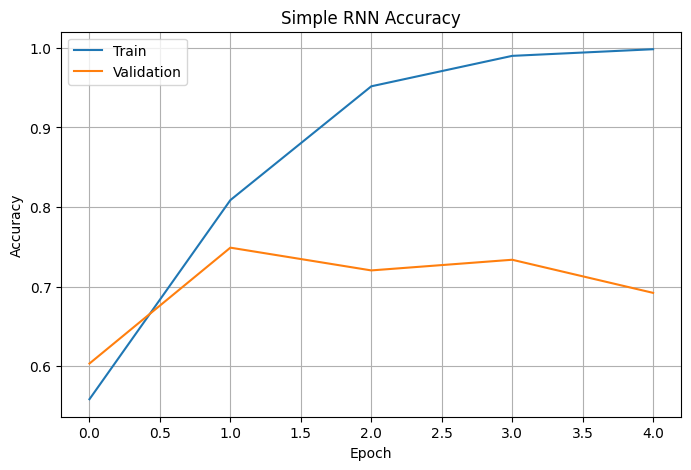

In [27]:
# RNN accuracy curve.

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    rnn_history.history["accuracy"],
    label="Train"
)

plt.plot(
    rnn_history.history["val_accuracy"],
    label="Validation"
)

plt.title("Simple RNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [28]:
# RNN accuracy curve.

# plt.plot(rnn_history.history["accuracy"], label="Train")
# plt.plot(rnn_history.history["val_accuracy"], label="Validation")
# plt.title("Simple RNN Accuracy")
# plt.xlabel("Epoch")
# plt.ylabel("Accuracy")
# plt.legend()
# plt.show()

# 8. Model 2 — LSTM

LSTM is a special type of RNN.

It uses gates to control information.

Simplified idea:

```text
Previous information
        +
New information
        ↓
      LSTM
        ↓
Useful information
```

Main gates:

- Forget gate
- Input gate
- Output gate

In [29]:
# LSTM

lstm_model = Sequential([
    Embedding(VOCAB_SIZE, EMBEDDING_DIM),
    LSTM(RNN_UNITS),
    Dense(1, activation="sigmoid")
])

lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [31]:
import tensorflow as tf
import numpy as np

BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

X_train_np = X_train.astype(str).to_numpy()
X_val_np = X_val.astype(str).to_numpy()
X_test_np = X_test.astype(str).to_numpy()

y_train_np = y_train.astype("int32").to_numpy()
y_val_np = y_val.astype("int32").to_numpy()
y_test_np = y_test.astype("int32").to_numpy()

print(X_train_np.dtype)
print(y_train_np.dtype)

object
int32


In [32]:
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_np, y_train_np)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val_np, y_val_np)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test_np, y_test_np)
)

train_dataset = (
    train_dataset
    .shuffle(10000)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_dataset = (
    val_dataset
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_dataset = (
    test_dataset
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

In [33]:
for text_batch, label_batch in train_dataset.take(1):
    print("Text shape:", text_batch.shape)
    print("Text dtype:", text_batch.dtype)
    print("Label shape:", label_batch.shape)
    print("Label dtype:", label_batch.dtype)

Text shape: (64,)
Text dtype: <dtype: 'string'>
Label shape: (64,)
Label dtype: <dtype: 'int32'>


In [34]:
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    Dense
)

inputs = Input(
    shape=(),
    dtype=tf.string,
    name="text"
)

x = vectorizer(inputs)

x = Embedding(
    input_dim=MAX_VOCAB_SIZE,
    output_dim=128,
    mask_zero=True
)(x)

x = LSTM(64)(x)

outputs = Dense(
    1,
    activation="sigmoid"
)(x)

lstm_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="LSTM_IMDB"
)

In [35]:
lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [37]:
lstm_history = lstm_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 61s 184ms/step - accuracy: 0.7661 - loss: 0.4866 - val_accuracy: 0.8548 - val_loss: 0.3478
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 57s 182ms/step - accuracy: 0.8957 - loss: 0.2701 - val_accuracy: 0.8656 - val_loss: 0.3320
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 57s 180ms/step - accuracy: 0.9404 - loss: 0.1707 - val_accuracy: 0.8742 - val_loss: 0.3439
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 35s 112ms/step - accuracy: 0.9646 - loss: 0.1070 - val_accuracy: 0.8668 - val_loss: 0.4125
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 40s 127ms/step - accuracy: 0.9679 - loss: 0.0955 - val_accuracy: 0.8478 - val_loss: 0.4462


In [38]:
print(lstm_history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


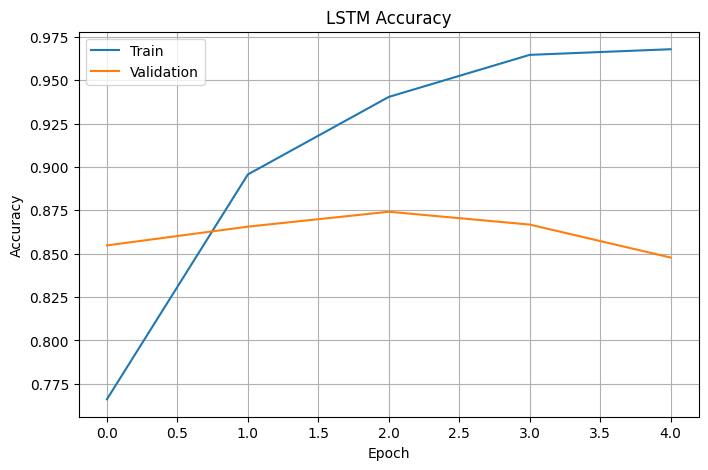

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    lstm_history.history["accuracy"],
    label="Train"
)

plt.plot(
    lstm_history.history["val_accuracy"],
    label="Validation"
)

plt.title("LSTM Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [40]:
# Train LSTM.

# lstm_history = lstm_model.fit(
#     X_train,
#     y_train,
#     validation_data=(X_val, y_val),
#     epochs=EPOCHS,
#     batch_size=BATCH_SIZE
# )

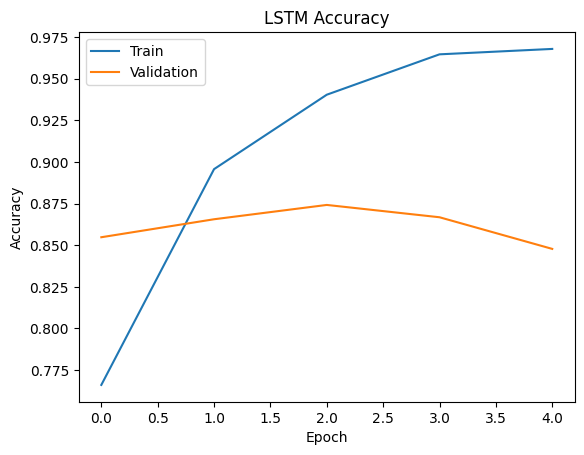

In [41]:
# LSTM accuracy curve.

plt.plot(lstm_history.history["accuracy"], label="Train")
plt.plot(lstm_history.history["val_accuracy"], label="Validation")
plt.title("LSTM Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# 9. Model 3 — GRU

GRU is another gated RNN.

Simplified idea:

```text
Previous information
        +
New information
        ↓
       GRU
        ↓
Updated information
```

GRU uses two important mechanisms:

- Update gate
- Reset gate

The code is intentionally similar to the RNN and LSTM code so the architectural difference is easy to see.

In [42]:
# GRU

gru_model = Sequential([
    Embedding(VOCAB_SIZE, EMBEDDING_DIM),
    GRU(RNN_UNITS),
    Dense(1, activation="sigmoid")
])

gru_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

gru_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [44]:
# Train GRU.

# gru_history = gru_model.fit(
#     X_train,
#     y_train,
#     validation_data=(X_val, y_val),
#     epochs=EPOCHS,
#     batch_size=BATCH_SIZE
# )

In [47]:
for text_batch, label_batch in train_dataset.take(1):
    print("Text:", text_batch.shape, text_batch.dtype)
    print("Label:", label_batch.shape, label_batch.dtype)

Text: (64,) <dtype: 'string'>
Label: (64,) <dtype: 'int32'>


In [48]:
print(vectorizer)
print("Vocabulary size:", len(vectorizer.get_vocabulary()))

<TextVectorization name=text_vectorization_1, built=True>
Vocabulary size: 20000


In [49]:
for text_batch, _ in train_dataset.take(1):
    vectorized = vectorizer(text_batch)
    print("Vectorized shape:", vectorized.shape)

Vectorized shape: (64, 250)


In [50]:
gru_history = gru_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 42s 127ms/step - accuracy: 0.7102 - loss: 0.5391 - val_accuracy: 0.8372 - val_loss: 0.3825
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 42s 135ms/step - accuracy: 0.8929 - loss: 0.2723 - val_accuracy: 0.8062 - val_loss: 0.4248
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 38s 120ms/step - accuracy: 0.9352 - loss: 0.1769 - val_accuracy: 0.8706 - val_loss: 0.3271
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 39s 126ms/step - accuracy: 0.9646 - loss: 0.1029 - val_accuracy: 0.8630 - val_loss: 0.4063
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 45s 145ms/step - accuracy: 0.9825 - loss: 0.0552 - val_accuracy: 0.8620 - val_loss: 0.4725


In [ ]:
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Embedding, GRU, Dense

inputs = Input(
    shape=(),
    dtype=tf.string,
    name="text"
)

x = vectorizer(inputs)

print("After vectorizer:", x.shape)

x = Embedding(
    input_dim=MAX_VOCAB_SIZE,
    output_dim=128,
    mask_zero=True,
    name="embedding"
)(x)

print("After embedding:", x.shape)

x = GRU(
    64,
    name="gru"
)(x)

outputs = Dense(
    1,
    activation="sigmoid",
    name="output"
)(x)

gru_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="GRU_IMDB"
)

gru_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

gru_model.summary()

Model: "GRU_IMDB"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 250)       │          0 │ text[0][0]        │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_6         │ (None, 250, 128)  │  2,560,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 250)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 64)        │     37,248 │ embedding_6[0][0… │
│                     │                   │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 1)         │         65 │ gru_1[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,597,313 (9.91 MB)

 Trainable params: 2,597,313 (9.91 MB)

 Non-trainable params: 0 (0.00 B)

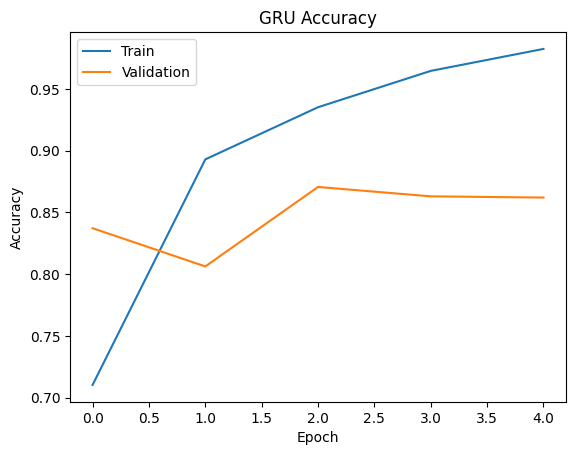

In [51]:
# GRU accuracy curve.

plt.plot(gru_history.history["accuracy"], label="Train")
plt.plot(gru_history.history["val_accuracy"], label="Validation")
plt.title("GRU Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# 10. Compare validation accuracy

All three models used:

- Same dataset
- Same split
- Same vocabulary
- Same sequence length
- Same embedding size
- Same units
- Same optimizer
- Same epochs
- Same batch size

This makes the comparison easier to interpret.

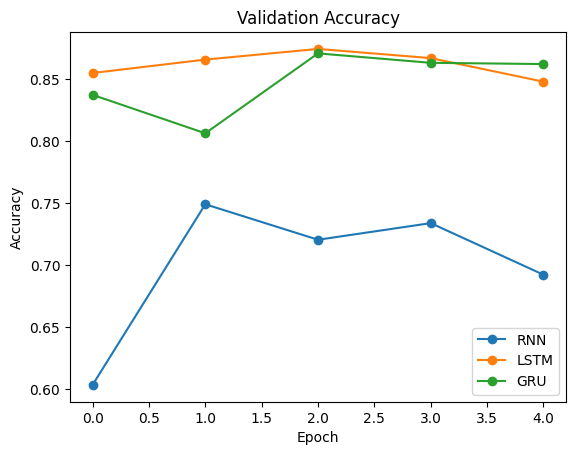

In [52]:
plt.plot(rnn_history.history["val_accuracy"], marker="o", label="RNN")
plt.plot(lstm_history.history["val_accuracy"], marker="o", label="LSTM")
plt.plot(gru_history.history["val_accuracy"], marker="o", label="GRU")

plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

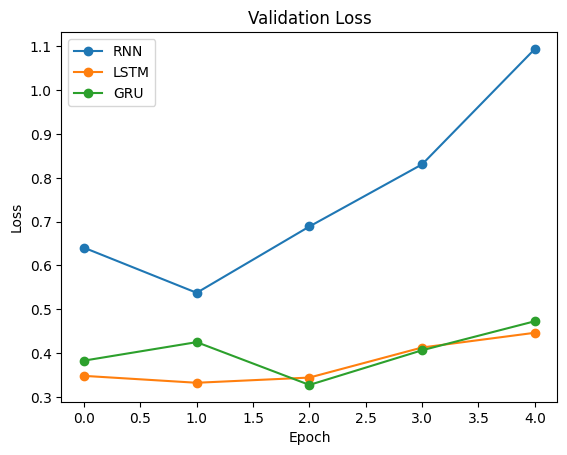

In [53]:
plt.plot(rnn_history.history["val_loss"], marker="o", label="RNN")
plt.plot(lstm_history.history["val_loss"], marker="o", label="LSTM")
plt.plot(gru_history.history["val_loss"], marker="o", label="GRU")

plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# 11. Final Test Evaluation

Now evaluate on the test set.

We calculate:

- Accuracy
- Precision
- Recall
- F1-score

The test set is used here only for final evaluation.

In [ ]:
# def evaluate_model(model, X, y):
#     # Get probability for Positive class.
#     probability = model.predict(X, verbose=0).ravel()

#     # Convert probability into 0 or 1.
#     prediction = (probability >= 0.5).astype(int)

#     result = {
#         "Accuracy": accuracy_score(y, prediction),
#         "Precision": precision_score(y, prediction),
#         "Recall": recall_score(y, prediction),
#         "F1": f1_score(y, prediction)
#     }

#     return result, prediction, probability

In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def evaluate_model(model, X, y):
    # Convert text to a normal NumPy string array
    X_np = X.astype(str).to_numpy()
    y_np = y.astype("int32").to_numpy()

    # Predict
    probability = model.predict(
        X_np,
        verbose=0
    ).ravel()

    # Convert probability to 0/1
    prediction = (probability >= 0.5).astype(int)

    # Metrics
    result = {
        "accuracy": accuracy_score(y_np, prediction),
        "precision": precision_score(y_np, prediction),
        "recall": recall_score(y_np, prediction),
        "f1": f1_score(y_np, prediction),
        "roc_auc": roc_auc_score(y_np, probability)
    }

    return result, prediction, probability

In [57]:
rnn_result, rnn_pred, rnn_prob = evaluate_model(rnn_model, X_test, y_test)
lstm_result, lstm_pred, lstm_prob = evaluate_model(lstm_model, X_test, y_test)
gru_result, gru_pred, gru_prob = evaluate_model(gru_model, X_test, y_test)

results = pd.DataFrame(
    [rnn_result, lstm_result, gru_result],
    index=["RNN", "LSTM", "GRU"]
)

results

,accuracy,precision,recall,f1,roc_auc
RNN,0.67936,0.667164,0.71584,0.690645,0.744677
LSTM,0.82600,0.856643,0.78304,0.818189,0.895079
GRU,0.83584,0.858558,0.80416,0.830469,0.909609


# 12. Metric meanings

### Accuracy
How many predictions were correct overall.

### Precision
When the model says **Positive**, how often is it correct?

### Recall
Of all actual **Positive** reviews, how many did the model find?

### F1-score
Balances precision and recall.

Do not compare models using accuracy alone.

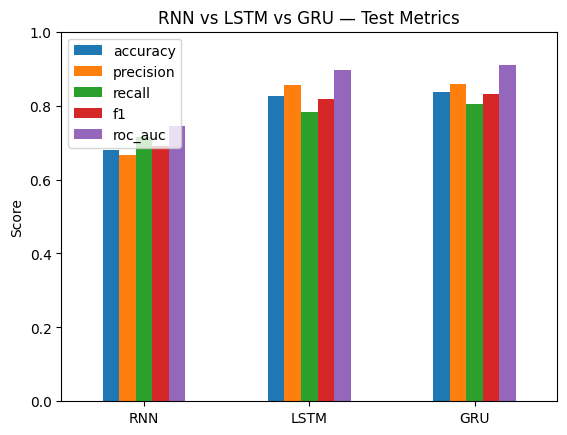

In [58]:
# Visual comparison.

results.plot(kind="bar")
plt.title("RNN vs LSTM vs GRU — Test Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

# 13. Classification Reports

The report shows metrics separately for Negative and Positive classes.

In [59]:
print("===== RNN =====")
print(classification_report(
    y_test, rnn_pred,
    target_names=["Negative", "Positive"]
))

print("===== LSTM =====")
print(classification_report(
    y_test, lstm_pred,
    target_names=["Negative", "Positive"]
))

print("===== GRU =====")
print(classification_report(
    y_test, gru_pred,
    target_names=["Negative", "Positive"]
))

===== RNN =====
              precision    recall  f1-score   support

    Negative       0.69      0.64      0.67     12500
    Positive       0.67      0.72      0.69     12500

    accuracy                           0.68     25000
   macro avg       0.68      0.68      0.68     25000
weighted avg       0.68      0.68      0.68     25000

===== LSTM =====
              precision    recall  f1-score   support

    Negative       0.80      0.87      0.83     12500
    Positive       0.86      0.78      0.82     12500

    accuracy                           0.83     25000
   macro avg       0.83      0.83      0.83     25000
weighted avg       0.83      0.83      0.83     25000

===== GRU =====
              precision    recall  f1-score   support

    Negative       0.82      0.87      0.84     12500
    Positive       0.86      0.80      0.83     12500

    accuracy                           0.84     25000
   macro avg       0.84      0.84      0.84     25000
weighted avg       0.84  

# 14. Confusion Matrix

A confusion matrix shows the four types of results:

```text
                 Predicted
               Negative Positive
Actual Negative    TN       FP
Actual Positive    FN       TP
```

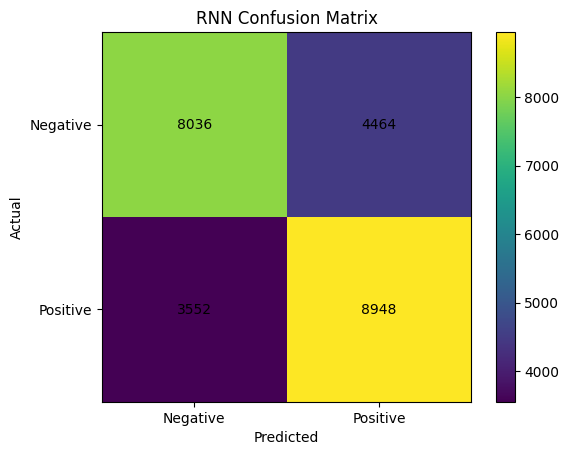

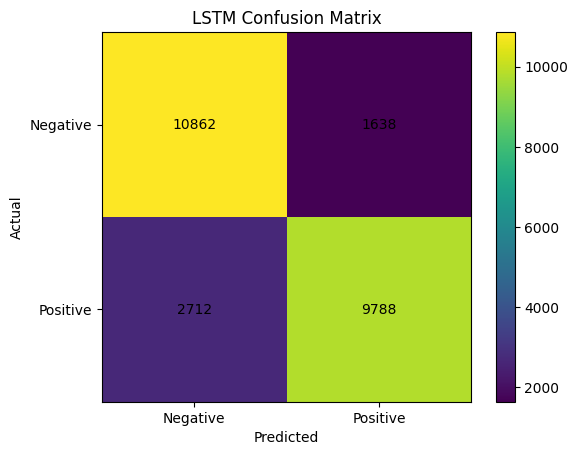

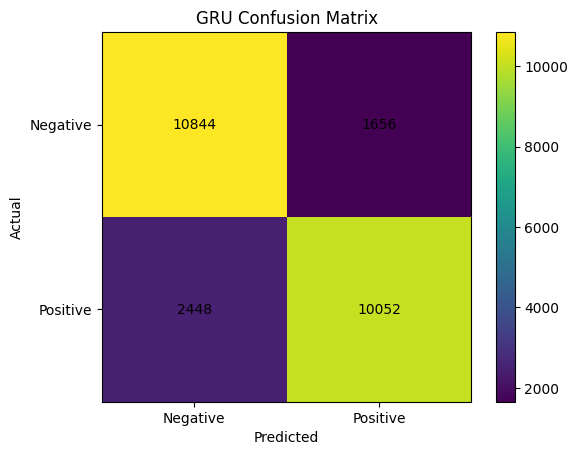

In [60]:
def show_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)

    plt.imshow(cm)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.xticks([0, 1], ["Negative", "Positive"])
    plt.yticks([0, 1], ["Negative", "Positive"])

    for row in range(2):
        for col in range(2):
            plt.text(col, row, cm[row, col],
                     ha="center", va="center")

    plt.colorbar()
    plt.show()

show_confusion_matrix(y_test, rnn_pred, "RNN Confusion Matrix")
show_confusion_matrix(y_test, lstm_pred, "LSTM Confusion Matrix")
show_confusion_matrix(y_test, gru_pred, "GRU Confusion Matrix")

# 15. Parameter Comparison

All three models use the same embedding size and the same number of recurrent units.

But their internal structures are different, so their parameter counts are different.

In [61]:
parameter_table = pd.DataFrame({
    "Model": ["RNN", "LSTM", "GRU"],
    "Parameters": [
        rnn_model.count_params(),
        lstm_model.count_params(),
        gru_model.count_params()
    ]
})

parameter_table

,Model,Parameters
0,RNN,2572417
1,LSTM,2609473
2,GRU,2597313


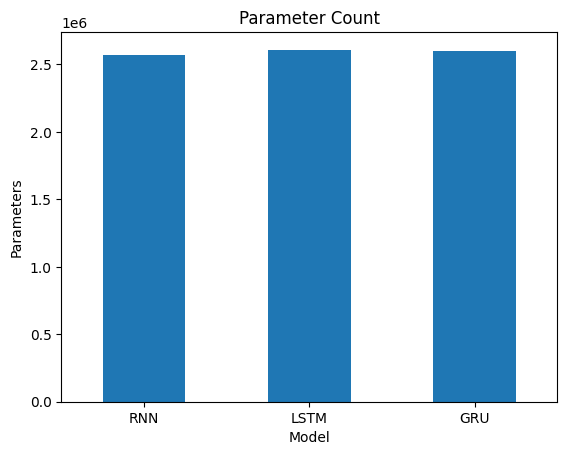

In [62]:
parameter_table.plot(
    x="Model",
    y="Parameters",
    kind="bar",
    legend=False
)

plt.title("Parameter Count")
plt.ylabel("Parameters")
plt.xticks(rotation=0)
plt.show()

# 16. Error Analysis

A wrong prediction is useful for learning.

We will print some reviews where each model made an incorrect prediction.

In [63]:
def show_errors(texts, labels, predictions, model_name, n=5):
    wrong = np.where(labels != predictions)[0][:n]

    print("=" * 80)
    print(model_name)
    print("=" * 80)

    for i in wrong:
        actual = "Positive" if labels[i] == 1 else "Negative"
        predicted = "Positive" if predictions[i] == 1 else "Negative"

        print("Actual   :", actual)
        print("Predicted:", predicted)
        print("Review   :", texts.iloc[i][:500])
        print("-" * 80)

show_errors(test_df["text"], y_test, rnn_pred, "RNN Errors")
show_errors(test_df["text"], y_test, lstm_pred, "LSTM Errors")
show_errors(test_df["text"], y_test, gru_pred, "GRU Errors")

RNN Errors
Actual   : Positive
Predicted: Negative
Review   : There are films that make careers. For George Romero, it was NIGHT OF THE LIVING DEAD; for Kevin Smith, CLERKS; for Robert Rodriguez, EL MARIACHI. Add to that list Onur Tukel's absolutely amazing DING-A-LING-LESS. Flawless film-making, and as assured and as professional as any of the aforementioned movies. I haven't laughed this hard since I saw THE FULL MONTY. (And, even then, I don't think I laughed quite this hard... So to speak.) Tukel's talent is considerable: DING-A-LING-LESS is so chock f
--------------------------------------------------------------------------------
Actual   : Negative
Predicted: Positive
Review   : Poor Shirley MacLaine tries hard to lend some gravitas to this mawkish, gag-inducing "feel-good" movie, but she's trampled by the run-away sentimentality of a film that's not the least bit grounded in reality.<br /><br />This was directed by Curtis Hanson? Did he have a lobotomy since we last heard from 

# 17. Predict a New Review

The model returns a probability.

```text
Probability >= 0.50 → Positive
Probability <  0.50 → Negative
```

In [73]:
def predict_review(model, text):
    # Model expects raw text because TextVectorization
    # is already inside the model.
    probability = model.predict(
        np.array([text], dtype=str),
        verbose=0
    )[0][0]

    label = "Positive" if probability >= 0.5 else "Negative"

    return label, float(probability)

# 18. Save Models and Results

In [67]:
inputs = tf.keras.Input(
    shape=(),
    dtype=tf.string,
    name="text"
)

x = vectorizer(inputs)

x = tf.keras.layers.Embedding(
    input_dim=MAX_VOCAB_SIZE,
    output_dim=128,
    mask_zero=True,
    name="embedding"
)(x)

x = tf.keras.layers.SimpleRNN(
    64,
    name="simple_rnn"
)(x)

outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid",
    name="output"
)(x)

rnn_model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="imdb_rnn"
)

rnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [68]:
inputs = tf.keras.Input(
    shape=(),
    dtype=tf.string,
    name="text"
)

x = vectorizer(inputs)

x = tf.keras.layers.Embedding(
    input_dim=MAX_VOCAB_SIZE,
    output_dim=128,
    mask_zero=True,
    name="embedding"
)(x)

x = tf.keras.layers.LSTM(
    64,
    name="lstm"
)(x)

outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid",
    name="output"
)(x)

lstm_model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="imdb_lstm"
)

lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [69]:
inputs = tf.keras.Input(
    shape=(),
    dtype=tf.string,
    name="text"
)

x = vectorizer(inputs)

x = tf.keras.layers.Embedding(
    input_dim=MAX_VOCAB_SIZE,
    output_dim=128,
    mask_zero=True,
    name="embedding"
)(x)

x = tf.keras.layers.GRU(
    64,
    name="gru"
)(x)

outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid",
    name="output"
)(x)

gru_model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="imdb_gru"
)

gru_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [71]:
vocab = vectorizer.get_vocabulary()

bad_chars = []

for i, word in enumerate(vocab):
    try:
        word.encode("cp1252")
    except UnicodeEncodeError:
        bad_chars.append((i, repr(word)))

print("Bad entries:", len(bad_chars))
print(bad_chars[:20])

Bad entries: 5
[(430, "np.str_('\\x96')"), (6018, "np.str_('\\x97')"), (6019, "np.str_('\\x85')"), (16657, "np.str_('\\x91the')"), (16658, "np.str_('\\x8ei\\x9eek')")]


In [72]:
vocab = vectorizer.get_vocabulary()

bad_chars = []

for i, word in enumerate(vocab):
    try:
        word.encode("cp1252")
    except UnicodeEncodeError:
        bad_chars.append((i, repr(word)))

print("Bad entries:", len(bad_chars))
print(bad_chars[:20])

Bad entries: 5
[(430, "np.str_('\\x96')"), (6018, "np.str_('\\x97')"), (6019, "np.str_('\\x85')"), (16657, "np.str_('\\x91the')"), (16658, "np.str_('\\x8ei\\x9eek')")]


# 19. Final Comparison Questions

After running the notebook, answer these from your actual results:

1. Which model has the highest test accuracy?
2. Which model has the highest F1-score?
3. Which model has the highest precision?
4. Which model has the highest recall?
5. Which model has the most parameters?
6. Which model trains fastest on your machine?
7. How do the validation curves differ?
8. Where does each model make mistakes?
9. Why can accuracy alone be insufficient?
10. How does the code change between RNN, LSTM and GRU?

**Do not assume a fixed winner before running the experiment.**

# 20. RNN vs LSTM vs GRU — Quick Revision

| Model | Simple idea | Gates | Main concept |
|---|---|---:|---|
| Simple RNN | Basic hidden-state memory | No | Simple sequence memory |
| LSTM | Controlled memory | 3 main gates | Cell state + gates |
| GRU | Simpler controlled memory | 2 main gates | Update + reset |

### Code difference

```python
# RNN
SimpleRNN(32)

# LSTM
LSTM(32)

# GRU
GRU(32)
```

The surrounding pipeline stays almost the same.

That is why this project is useful for understanding the practical difference between the three models.

# 21. Beginner Exercises

### Exercise 1
Change:

```python
RNN_UNITS = 32
```

to:

```python
RNN_UNITS = 64
```

Compare accuracy and parameter count.

### Exercise 2
Change:

```python
EMBEDDING_DIM = 64
```

to:

```python
EMBEDDING_DIM = 128
```

### Exercise 3
Change:

```python
MAX_LENGTH = 200
```

to:

```python
MAX_LENGTH = 100
```

### Exercise 4
Use `RMSprop` instead of `Adam`.

### Exercise 5
Add `Dropout`.

### Exercise 6
Find five reviews where the three models disagree.

### Exercise 7
Create your own final comparison table:

```text
Model | Parameters | Accuracy | Precision | Recall | F1
```

# 22. Viva / Interview Questions

### Basic
1. What is an RNN?
2. Why is RNN useful for text?
3. What is a hidden state?
4. What is an embedding?
5. What is TextVectorization?
6. What is an epoch?
7. What is a batch?
8. Why do we need validation data?

### LSTM
9. Why was LSTM introduced?
10. What is the cell state?
11. What is the forget gate?
12. What is the input gate?
13. What is the output gate?

### GRU
14. What is a GRU?
15. What is an update gate?
16. What is a reset gate?
17. How is GRU different from LSTM?

### Evaluation
18. What is accuracy?
19. What is precision?
20. What is recall?
21. What is F1-score?
22. What is a confusion matrix?

### Practical
23. Why use the same dataset for comparison?
24. Why keep the test set separate?
25. Why use sigmoid here?
26. Why use binary crossentropy?
27. Why compare parameter counts?

# 23. Dataset and Learning Resources

### Dataset
IMDb Reviews — TensorFlow Datasets:
https://www.tensorflow.org/datasets/catalog/imdb_reviews

### TensorFlow RNN guide
https://www.tensorflow.org/guide/keras/working_with_rnns

### SimpleRNN
https://keras.io/api/layers/recurrent_layers/simple_rnn/

### LSTM
https://keras.io/api/layers/recurrent_layers/lstm/

### GRU
https://keras.io/api/layers/recurrent_layers/gru/

### TensorFlow Text Classification
https://www.tensorflow.org/tutorials/keras/text_classification

### Recommended next projects

```text
Project 1
RNN vs LSTM vs GRU
        ↓
Project 2
LSTM + GRU + Attention
        ↓
Project 3
LSTM / GRU Time-Series Forecasting
        ↓
Project 4
Deployment + API
```

# Final Takeaway

Remember the complete pipeline:

```text
TEXT
 ↓
TEXT VECTORIZATION
 ↓
INTEGER SEQUENCE
 ↓
EMBEDDING
 ↓
RNN / LSTM / GRU
 ↓
DENSE
 ↓
SIGMOID
 ↓
POSITIVE / NEGATIVE
```

The key learning is:

```text
Simple RNN → basic sequence memory

LSTM → gated memory + cell state

GRU → gated memory with a simpler structure
```

Run the complete notebook and use the actual measured results to compare the three models.